# 2. Matching methods

A match is a table of `(source_id, target_id)` pairs plus the quantities the method measures. The
method decides the meaning of the result, so it is worth choosing deliberately. This notebook shows
each family on Riverton and draws the pairs as segments from source to target.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import urbanweave as uw

import tutorial_data as td          # Riverton, the synthetic town these tutorials use
from svgmap import Map              # small static SVG maps
from tutorial_data import show      # prints reports compactly

In [2]:
districts = td.districts()
tracts = td.tracts()
crashes = td.crashes()
stops = td.bus_stops()

## Points into polygons: `contain`

Each point goes to the polygon containing it. A point exactly on a shared boundary goes to one
polygon only, the one with the lowest target ID, so nothing is counted twice.

In [3]:
m = uw.match(crashes, districts, "contain", source_id="crash_id", target_id="district_id")
m.pairs["target_id"].value_counts()

target_id
OT    214
NG    118
RS     95
EF     92
MD     81
Name: count, dtype: int64

## Polygons onto polygons: one point, or overlap

A polygon can be represented by a single point, or split by area.

- **`centroid`**: the geometric centroid, which can fall outside a concave polygon.
- **`representative_point`**: a point guaranteed to be inside the polygon.
- **`area_overlap`**: the polygon is split among every target it overlaps, with
  `allocation_fraction` (its share of the source) and `overlap_measure` (m²).
- **`largest_overlap`**: the whole polygon goes to the target it overlaps most.

A U-shaped lot shows the difference between the first two: its centroid lies in the courtyard,
which belongs to another parcel.

In [4]:
from shapely.geometry import box
X, Y = td.X0, td.Y0
lot = box(X, Y, X + 300, Y + 200).difference(box(X + 100, Y + 60, X + 200, Y + 200))   # a U, open to the north
lots = td.gpd.GeoDataFrame({"lot": ["U"]}, geometry=[lot], crs=td.CRS)
parcels = td.gpd.GeoDataFrame({"target_id": ["courtyard", "building"]},
                              geometry=[box(X + 90, Y + 50, X + 210, Y + 210), box(X - 10, Y - 10, X + 310, Y + 210).difference(box(X + 90, Y + 50, X + 210, Y + 210))],
                              crs=td.CRS)
for method in ("centroid", "representative_point"):
    print(method, "->", uw.match(lots, parcels, method).pairs["target_id"].tolist())

centroid -> ['courtyard']
representative_point -> ['building']


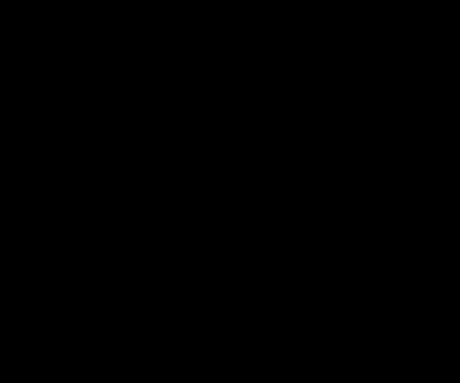

In [5]:
points = td.gpd.GeoDataFrame({"point": ["centroid", "representative point"]},
                              geometry=[lot.centroid, lot.representative_point()], crs=td.CRS)
(Map("A U-shaped lot (outlined): its centroid falls in the courtyard", width=460)
 .fill(parcels, "target_id", legend="parcel")
 .outline(lots, width=2.5)
 .dots(points, radius=4.5, label="point"))

Census tracts onto districts with `area_overlap`: each tract is split among the districts it
overlaps. Tract T02, for example, lies 95.5% in Mill District and 4.5% in Old Town.

In [6]:
m = uw.match(tracts, districts, "area_overlap", source_id="tract_id", target_id="district_id")
print(len(tracts), "tracts,", len(m.pairs), "pairs")
m.pairs.sort_values("source_id").head(6).round(3)

18 tracts, 33 pairs


,source_id,target_id,allocation_fraction,overlap_measure
21,T00,MD,1.000,387082.300
22,T01,MD,1.000,288226.914
23,T02,MD,0.955,302153.377
6,T02,OT,0.045,14242.011
24,T03,MD,0.093,37603.582
28,T03,RS,0.719,290450.736


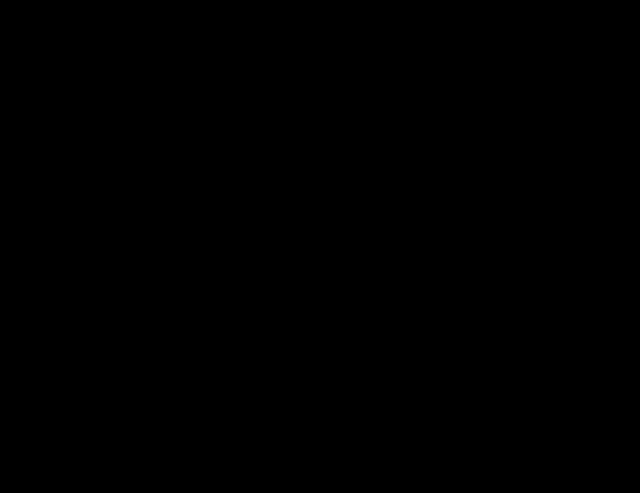

In [7]:
parts = m.pairs.groupby("source_id")["target_id"].nunique().rename("districts").astype(str)
split = tracts.merge(parts, left_on="tract_id", right_index=True)
(Map("Census tracts by the number of districts they are split among")
 .fill(split, "districts", scheme="categorical", order=["1", "2", "3"], legend="districts per tract",
       tooltip=["tract_id", "population"])
 .outline(districts, label="name", width=2.2))

In [8]:
largest = uw.match(tracts, districts, "largest_overlap", source_id="tract_id", target_id="district_id")
largest.pairs.head()

,source_id,target_id,allocation_fraction,overlap_measure
0,T06,NG,1.0,184869.275414
1,T07,NG,1.0,238644.864621
2,T12,NG,1.0,295623.508160
3,T13,NG,1.0,317701.266486
4,T14,NG,1.0,185747.371255


## Nearest, within a distance

`nearest` finds each source's nearest target, measured in metres. `max_distance` makes the
threshold explicit and inclusive: a crash farther than 150 m from every bus stop is reported as
unmatched rather than silently attached to a distant stop.

In [9]:
m = uw.match(crashes, stops, "nearest", source_id="crash_id", target_id="stop_id", max_distance=150)
show(m.report["sources"]["unmatched"])

{
 "beyond_max_distance": {
  "count": 464,
  "sample": ["C0000", "C0003", "C0005", "C0006", "C0007", "C0008", "C0009", "C0012", "C0014", "C0015"]
 }
}


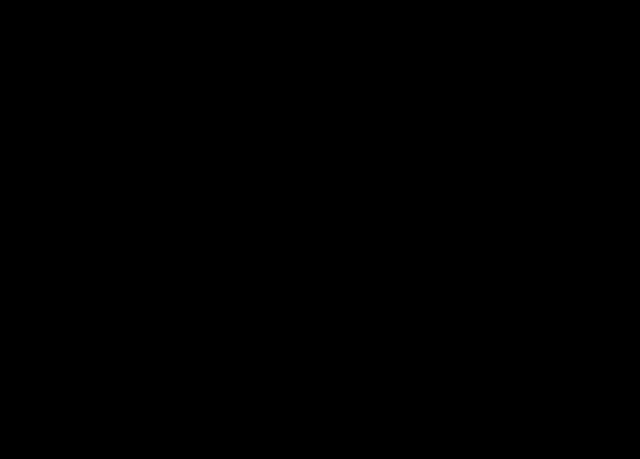

In [10]:
(Map("Each crash to its nearest bus stop, within 150 m")
 .outline(districts, label="name")
 .links(m)
 .dots(crashes, radius=1.3)
 .dots(stops, radius=5, label="stop_id"))

`within_distance` gives each source to *every* target within reach. With `split=True` (the default)
a crash near two stops counts half for each, so totals are conserved; with `split=False` each stop
gets the whole crash, which answers "how many crashes happened near this stop" but replicates
crashes. The report says which.

In [11]:
near = uw.aggregate(uw.match(crashes, stops, "within_distance", target_id="stop_id", distance=200, split=False),
                    None, [uw.count(as_="crashes_within_200m", fill_empty=0)])
shared = uw.aggregate(uw.match(crashes, stops, "within_distance", target_id="stop_id", distance=200),
                      None, [uw.weighted_count(as_="crash_share", fill_empty=0)])
print("replicated total:", near["crashes_within_200m"].sum(), " split total:", round(shared["crash_share"].sum(), 6))
show(uw.report_of(near)["match"]["notes"])

replicated total: 184  split total: 178.0
{
 "replicating": true
}


## Smoothing: the Gaussian kernel

`gaussian` spreads each point over nearby targets with weights from a Gaussian of standard deviation
`bandwidth` (metres), normalized so each point's weights sum to 1. Points with no target within
about 3σ are dropped by default and reported.

380 cells; total intensity 600.0 of 600 crashes


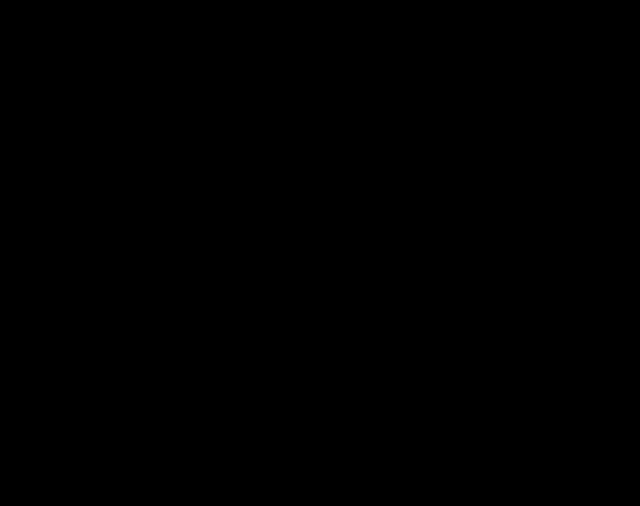

In [12]:
cells = uw.targets.h3_cells(crashes.to_crs(4326), 10)
smooth = uw.aggregate(uw.match(crashes, cells, "gaussian", bandwidth=120), None,
                      [uw.weighted_count(as_="crash_intensity", fill_empty=0)])
print(len(cells), "cells; total intensity", round(smooth["crash_intensity"].sum(), 3), "of", len(crashes), "crashes")
(Map("Crash intensity, Gaussian kernel (σ = 120 m) on H3 resolution 10")
 .fill(smooth, "crash_intensity", legend="crashes (smoothed) per cell")
 .outline(districts, label="name"))

**Next:** [3. Aggregation and reports](03_aggregation_and_reports.ipynb).